# SNE and t-SNE from scratch

Each of the 705 distinct base-stat lines of the first 721 Pokémon is a point in six dimensions. Can they be drawn on a page so that Pokémon with similar stats sit together? Stochastic neighbor embedding (SNE; Hinton and Roweis 2002) and its successor t-SNE (van der Maaten and Hinton 2008) are built for this question. This notebook writes both from their papers' equations, checks every piece (gradients by finite differences, probabilities and gradients against scikit-learn), shows the crowding problem that t-SNE was designed to fix, and scores the maps by how well they keep neighbors.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from maps import colors, data, draw, figures, ranks, sne, study

plt.rcParams.update(draw.RC)
plt.rcParams["figure.dpi"] = 80
names, stats, groups = data.pokemon()
print(f"{len(names)} stat lines; {sum(len(g) > 1 for g in groups)} are shared by two or more species, for example {groups[[len(g) for g in groups].index(6)]}")

705 stat lines; 10 are shared by two or more species, for example ['Mew', 'Celebi', 'Jirachi', 'Manaphy', 'ShayminLand Forme', 'Victini']


## Neighbor distributions

SNE turns distances into probabilities. Point i picks a neighbor j with probability

p(j | i) = exp(−|xᵢ − xⱼ|² / 2σᵢ²) / Σ_{k≠i} exp(−|xᵢ − x_k|² / 2σᵢ²),

a Gaussian centered on i. Its width σᵢ is set so that the **perplexity** 2^{H(Pᵢ)}, with H the entropy in bits, equals a chosen number: the effective number of neighbors. Entropy rises with σ, so bisection finds σᵢ.

A worked case: on a line, point 0 at 0 has neighbors at +1 and −1 and one far away at 10. Perplexity 2 means two effective neighbors, and the two near points should get about 1/2 each.

In [2]:
x = np.array([[0.0], [1.0], [-1.0], [10.0]])
p, betas = sne.conditional_p(sne.sq_distances(x), perplexity=2.0)
print("p(. | 0) =", p[0].round(6), f"  perplexity {2 ** sne.entropy_bits(p[0]):.6f}")
print("p(. | 3) =", p[3].round(6), "  (the far point spreads its choice by distance)")

p(. | 0) = [0.  0.5 0.5 0. ]   perplexity 2.000000
p(. | 3) = [0.205465 0.745059 0.049476 0.      ]   (the far point spreads its choice by distance)


## The cost and its gradient

A **map** places point i at yᵢ in the plane, and defines q(j | i) the same way with a fixed width (variance 1/2). SNE minimizes C = Σᵢ KL(Pᵢ ‖ Qᵢ), the sum of Kullback-Leibler divergences. KL is asymmetric: putting true neighbors far apart (large p, small q) costs a lot, putting strangers close (small p, large q) costs little. So SNE cares most about keeping neighbors together. The gradient has a spring form:

∂C/∂yᵢ = 2 Σⱼ (p(j|i) − q(j|i) + p(i|j) − q(i|j)) (yᵢ − yⱼ).

t-SNE changes two things. It uses one joint distribution, pᵢⱼ = (p(j|i) + p(i|j)) / 2n, which makes the gradient simpler; that alone is **symmetric SNE**, with ∂C/∂yᵢ = 4 Σⱼ (pᵢⱼ − qᵢⱼ)(yᵢ − yⱼ). And on the map it replaces the Gaussian by a Student t with one degree of freedom, qᵢⱼ ∝ (1 + |yᵢ − yⱼ|²)⁻¹, giving

∂C/∂yᵢ = 4 Σⱼ (pᵢⱼ − qᵢⱼ)(yᵢ − yⱼ)(1 + |yᵢ − yⱼ|²)⁻¹.

Each formula is checked against central finite differences of its own cost:

In [3]:
rng = np.random.default_rng(0)
x, y = rng.normal(size=(30, 4)), rng.normal(size=(30, 2))
p_cond = sne.conditional_p(sne.sq_distances(x), 8.0)[0]
h = 1e-6
for kind in ("sne", "ssne", "tsne"):
    target = p_cond if kind == "sne" else sne.joint_p(p_cond)
    _, grad = sne.cost_grad(kind, y, target)
    numeric = np.zeros_like(y)
    for i in range(30):
        for c in range(2):
            up, down = y.copy(), y.copy()
            up[i, c] += h
            down[i, c] -= h
            numeric[i, c] = (sne.cost_grad(kind, up, target)[0] - sne.cost_grad(kind, down, target)[0]) / (2 * h)
    print(f"{kind:5} largest gradient {np.abs(grad).max():.3f}, largest difference from finite differences {np.abs(grad - numeric).max():.1e}")

sne   largest gradient 9.359, largest difference from finite differences 1.4e-08


ssne  largest gradient 0.358, largest difference from finite differences 5.6e-10
tsne  largest gradient 0.033, largest difference from finite differences 2.3e-10


## Against scikit-learn

scikit-learn's t-SNE has the same P and the same cost. Its internal functions `_joint_probabilities` and `_kl_divergence` take the same inputs, so the two implementations can be compared piece by piece. scikit-learn stops its σ search when the entropy is within 10⁻⁵, this package at 10⁻¹⁰, which explains the small difference in P. The differences are printed as bounds: scikit-learn computes them with BLAS and the C library, whose last bits vary between machines.

In [4]:
from scipy.spatial.distance import squareform
from sklearn.manifold._t_sne import _joint_probabilities, _kl_divergence

d2 = sne.sq_distances(stats)
P = sne.joint_p(sne.conditional_p(d2, 30.0)[0])
P_sk = squareform(_joint_probabilities(d2, 30.0, 0))
p_diff = np.abs(P - P_sk).max()
print(f"P: largest entry {P.max():.2e}, largest difference from scikit-learn {'below 1e-8' if p_diff < 1e-8 else f'{p_diff:.1e}'}")
y0 = np.random.default_rng(1).normal(size=(len(stats), 2))
cost, grad = sne.cost_grad("tsne", y0, P)
cost_sk, grad_sk = _kl_divergence(y0.ravel(), squareform(P, checks=False), 1, len(stats), 2)
grad_diff = np.abs(grad.ravel() - grad_sk).max()
print(f"cost {cost:.10f} vs {cost_sk:.10f}; gradient difference {'below 1e-16' if grad_diff < 1e-16 else f'{grad_diff:.1e}'}")

P: largest entry 6.22e-04, largest difference from scikit-learn below 1e-8
cost 3.2547377116 vs 3.2547377116; gradient difference below 1e-16


## The optimizer

`sne.embed` follows section 3.4 of the t-SNE paper: start from N(0, 10⁻⁴ I); multiply P by 4 for the first 50 iterations (early exaggeration); momentum 0.5 until iteration 250 and 0.8 after; learning rate 100 with Jacobs's adaptive gains; 1,000 iterations. Plain SNE gets the same optimizer, without the simulated annealing that Hinton and Roweis used, and with the learning rate divided by 2n, since its n conditional distributions carry 2n times the mass of the joint one.

## The crowding problem

Eleven points can be mutually equidistant in ten dimensions (the corners of a regular simplex) but not in two. Put a cloud of 20 points around each corner: 220 points in 11 equally separated clusters, each cloud about as wide as half the distance between corners. A map that keeps the small distances right must put moderately distant points much too far apart. A Gaussian on the map has no room for that: the many weak attractions between moderately distant points pull everything together. The Student t's heavy tail lets a moderate distance in the data become a large one on the map.

Two measures, for the data and each map: the **separation**, the mean distance between cluster centers divided by the mean distance from a point to its own center; and the share of points whose nearest neighbor is in their own cluster.

data             separation  2.29   nearest neighbor in own cluster 0.991


SNE              separation  7.87   nearest neighbor in own cluster 0.982
symmetric SNE    separation  8.41   nearest neighbor in own cluster 0.991
t-SNE            separation 20.00   nearest neighbor in own cluster 0.995


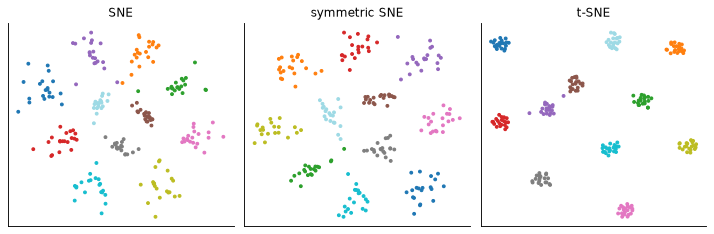

In [5]:
def separation(y, label):
    centers = np.array([y[label == c].mean(axis=0) for c in range(11)])
    within = np.mean([np.linalg.norm(y[label == c] - centers[c], axis=1).mean() for c in range(11)])
    return colors.distances(centers)[np.triu_indices(11, 1)].mean() / within


def nearest_same(y, label):
    d = colors.distances(y)
    np.fill_diagonal(d, np.inf)
    return np.mean(label[d.argmin(axis=1)] == label)


rng = np.random.default_rng(3)
corners = np.eye(11) * 5.0  # 11 corners of a regular simplex; the points span 10 dimensions
blobs = np.concatenate([c + rng.normal(scale=1.0, size=(20, 11)) for c in corners])
label = np.repeat(np.arange(11), 20)
blob_d2 = sne.sq_distances(blobs)
print(f"data             separation {separation(blobs, label):5.2f}   nearest neighbor in own cluster {nearest_same(blobs, label):.3f}")
runs = {kind: sne.embed(blob_d2, kind, perplexity=15, seed=0) for kind in ("sne", "ssne", "tsne")}
titles = {"sne": "SNE", "ssne": "symmetric SNE", "tsne": "t-SNE"}
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, (kind, run) in zip(axes, runs.items(), strict=True):
    ax.scatter(run.y[:, 0], run.y[:, 1], c=label, cmap="tab20", s=6)
    ax.set_title(titles[kind])
    ax.set_xticks([])
    ax.set_yticks([])
    print(f"{titles[kind]:16} separation {separation(run.y, label):5.2f}   nearest neighbor in own cluster {nearest_same(run.y, label):.3f}")
fig.tight_layout()

(Colors mark the eleven clusters only.) All three maps keep the clusters apart better than the data's own distances do, since a map has room to spread eleven groups in the plane. But the Gaussian maps leave their clusters wide, with narrow gaps between them, while t-SNE pulls each cluster tight and leaves gaps: its separation is 20, against about 8 for SNE and symmetric SNE. That is the effect of the heavy tail. A point a moderate distance away no longer attracts, so clusters stop pressing on each other.

## Pokémon stats

Now the 705 stat lines, at perplexity 30, with PCA for comparison. Each run is about 20 seconds.

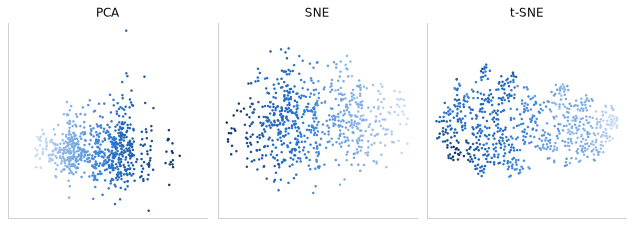

In [6]:
maps = study.embeddings("pokemon")
fig = figures.scatter_maps("pokemon")

Color is the stat total, light to dark. All three maps put weak Pokémon on one side and strong ones on the other; the total is the first principal component. SNE fills a disk evenly, the crowding seen above. t-SNE leaves gaps and pushes out a few groups: walls like Shuckle and the high-HP Chansey and Blissey, the frail fast ones, the legendaries.

## How well do the maps keep neighbors?

Venna and Kaski's trustworthiness T(k) asks whether the k points nearest to i on the map are near it in the data; continuity C(k) asks whether i's k nearest in the data are near it on the map. Venna et al. (2010) read these as the two kinds of error in retrieving neighbors from a map: precision and recall. They show that SNE's cost is a smoothed recall, and propose NeRV, which trades off the two. The rank scores here do not depend on the map's scale, so they compare maps of different kinds. The last column is t-SNE's cost evaluated on each map.

In [7]:
sne_res = study.sne_section()
for name in ("pokemon", "words"):
    print(name)
    print(f"  {'':14} {'T(5)':>6} {'T(10)':>6} {'T(20)':>6} {'C(5)':>6} {'C(10)':>6} {'C(20)':>6} {'t-SNE cost':>10}")
    for label, r in sne_res[name].items():
        print(f"  {label:14} " + " ".join(f"{v:6.3f}" for v in r["T"] + r["C"]) + f" {r['kl_t']:10.3f}")

pokemon
                   T(5)  T(10)  T(20)   C(5)  C(10)  C(20) t-SNE cost
  PCA             0.863  0.865  0.868  0.962  0.957  0.952      2.001
  SNE             0.887  0.886  0.885  0.974  0.968  0.959      1.728
  symmetric SNE   0.884  0.883  0.885  0.973  0.966  0.957      1.704
  t-SNE           0.982  0.966  0.947  0.965  0.952  0.938      0.932
words
                   T(5)  T(10)  T(20)   C(5)  C(10)  C(20) t-SNE cost
  PCA             0.618  0.630  0.625  0.695  0.680  0.667      2.461
  SNE             0.688  0.677  0.663  0.847  0.787  0.730      2.105
  symmetric SNE   0.682  0.665  0.648  0.846  0.784  0.729      2.111
  t-SNE           0.859  0.766  0.689  0.817  0.744  0.681      1.074


On both sets t-SNE is the most trustworthy map and the Gaussian maps (SNE, symmetric SNE) the most continuous. PCA is the least trustworthy; its continuity falls between the others' on the Pokémon and below them on the words. That is the trade-off Venna and Kaski describe: SNE, a recall method, keeps true neighbors together at the price of showing false ones. t-SNE gives up some continuity at k = 20 for much higher trustworthiness.

The precision-recall view of Venna et al. (section 2.1 of their paper): call a point's 20 nearest in the data its relevant neighbors, retrieve its k nearest on the map, and average precision and recall over points as k grows.

PCA            precision at 1 retrieved 0.343;  recall at 70 and 100 retrieved 0.765, 0.882


SNE            precision at 1 retrieved 0.482;  recall at 70 and 100 retrieved 0.807, 0.895
symmetric SNE  precision at 1 retrieved 0.472;  recall at 70 and 100 retrieved 0.801, 0.893


t-SNE          precision at 1 retrieved 0.979;  recall at 70 and 100 retrieved 0.777, 0.831


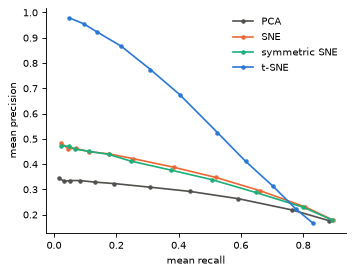

In [8]:
data_dist = colors.distances(stats)
retrieved = [1, 2, 3, 5, 8, 12, 20, 30, 45, 70, 100]
fig, ax = plt.subplots(figsize=(4.5, 3.5))
for color, name in zip(["#52514e", "#eb6834", "#1baf7a", "#2a78d6"], maps, strict=True):
    prec, rec = ranks.precision_recall(data_dist, colors.distances(maps[name]), 20, retrieved)
    ax.plot(rec, prec, "o-", color=color, ms=3, lw=1.5, label=name)
    print(f"{name:14} precision at 1 retrieved {prec[0]:.3f};  recall at 70 and 100 retrieved {rec[-2]:.3f}, {rec[-1]:.3f}")
ax.set_xlabel("mean recall")
ax.set_ylabel("mean precision")
ax.legend(frameon=False)
fig.tight_layout()

t-SNE's nearest point on the map is one of the 20 true neighbors 98% of the time, against under half the time for the Gaussian maps, and its curve lies far above theirs at small retrievals. The curves cross near recall 0.75. Retrieving 70 or 100 points, SNE recovers more of the true neighbors (recall 0.81 and 0.90, against 0.78 and 0.83 for t-SNE). The Gaussian maps' continuity shows up there, in the wide neighborhoods.

## scikit-learn's run

As a last check of the whole optimizer, scikit-learn's exact t-SNE with the same settings (perplexity 30, early exaggeration 4, learning rate 100, random start) should reach a similar cost. Its random start and its optimizer details differ, so the maps differ; the cost and the rank scores are what to compare. The numbers are rounded because scikit-learn's run uses BLAS, whose last bits vary between machines.

In [9]:
from sklearn.manifold import TSNE

sk = TSNE(perplexity=30, method="exact", init="random", random_state=0, learning_rate=100, early_exaggeration=4, max_iter=1000)
y_sk = sk.fit_transform(stats)
ours = sne_res["pokemon"]["t-SNE"]
tc = ranks.trust_continuity(data_dist, colors.distances(y_sk), [10])
print(f"cost: here {ours['kl_t']:.2f}, scikit-learn {sk.kl_divergence_:.2f}")
print(f"T(10): here {ours['T'][1]:.2f}, scikit-learn {tc['trust'][0]:.2f};  C(10): here {ours['C'][1]:.2f}, scikit-learn {tc['cont'][0]:.2f}")

cost: here 0.93, scikit-learn 0.93
T(10): here 0.97, scikit-learn 0.97;  C(10): here 0.95, scikit-learn 0.95


## Words

The same maps of the 400 Codenames words (256-dimensional wordllama vectors). Here are the t-SNE map's neighbors of a few words, against their nearest in the vectors themselves.

In [10]:
words, wv = data.codenames_words()
wmaps = study.embeddings("words")
vec_dist, map_dist = colors.distances(wv), colors.distances(wmaps["t-SNE"])
for w in ("doctor", "moon", "bank", "dragon"):
    i = words.index(w)
    near = [words[j] for j in np.argsort(vec_dist[i])[1:5]]
    on_map = [words[j] for j in np.argsort(map_dist[i])[1:5]]
    print(f"{w:8} vectors: {', '.join(near):40} map: {', '.join(on_map)}")

doctor   vectors: patient, hospital, blood, knee           map: patient, hospital, nurse, middle
moon     vectors: satellite, crystal, rocket, boat         map: satellite, crystal, stone, stick
bank     vectors: honey, tank, wire, bone                  map: honey, horse, arsenal, dog
dragon   vectors: monster, character, giant, brother       map: monster, giant, planet, sun


## Variations and open questions

- **Perplexity.** Every map here uses 30. Sweeping it from 5 to 100 and plotting T(10) and C(10) would show how much the trade-off moves.
- **NeRV.** Venna et al.'s NeRV minimizes λ KL(P‖Q) + (1 − λ) KL(Q‖P). λ = 1 is SNE. The gradient of the second term is a few lines on top of `sne_q_grad`; a sweep of λ would trace the precision-recall frontier on these data.
- **Starting points.** t-SNE's cost is not convex. Twenty seeds would show how far apart the local minima are, in cost and in T and C.
- **Standardized stats.** The stats share a unit (points), so they are used raw; dividing each by its spread would weight Speed and HP equally and change the neighbors.

## The numbers the README quotes

In [11]:
assert study.same(study.rounded(sne_res), study.stored()["sne"])
stored_maps = study.stored_maps()
assert all(np.allclose(stored_maps[k], v, atol=1e-4) for k, v in study.map_arrays().items())
print("sne section and the maps match maps/results")

sne section and the maps match maps/results
